# Gemini 3 with LangChain 

This notebook demonstrates all key features of Google's Gemini 3 model family using LangChain.

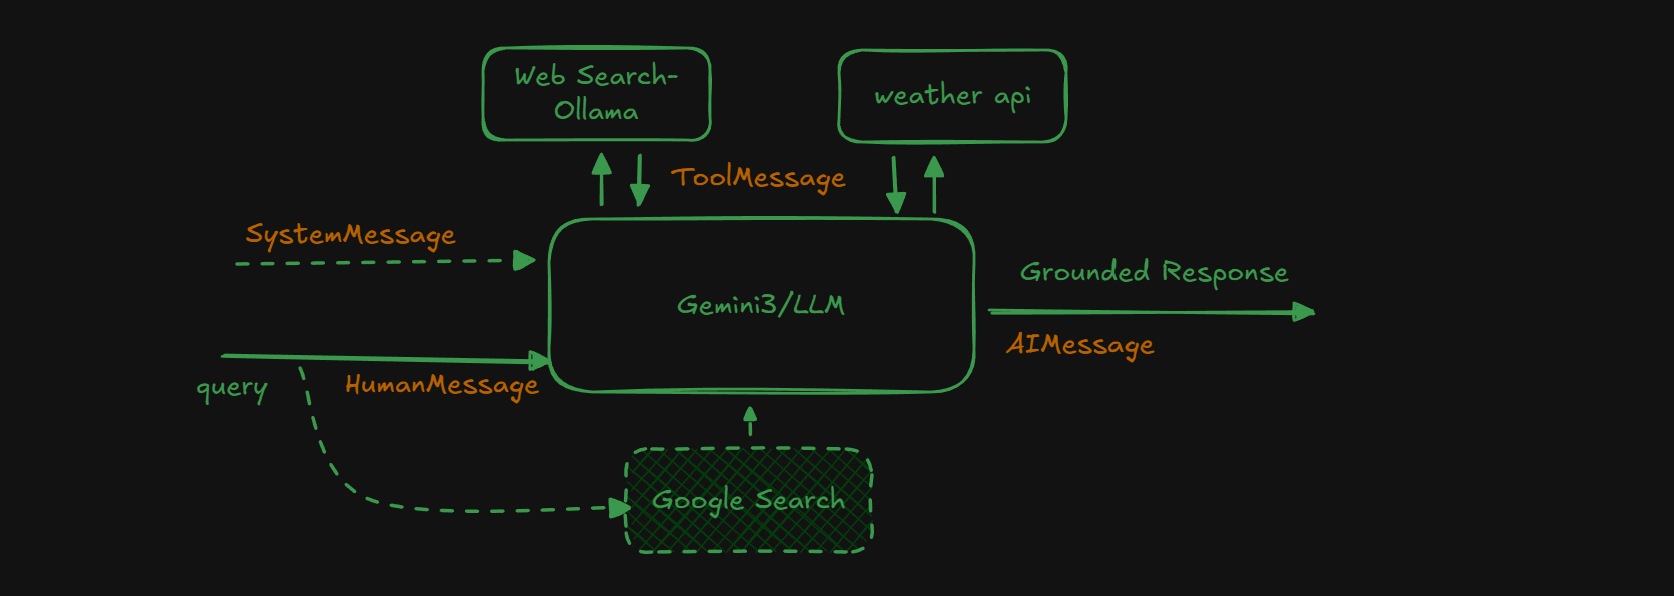

## Gemini 3 Overview

**gemini-3.1-flash-lite-preview** is Google's most cost-efficient Gemini model, optimized for low latency use cases for high-volume, cost-sensitive LLM traffic. It provides a significant quality increase over Gemini 2.0/2.5 Flash-Lite models, matching Gemini 2.5 Flash performance across key capability areas.

### Key Features
- **Advanced Reasoning**: Dynamic thinking process with configurable thinking levels
- **1M Token Context**: Up to 1 million token input, 64k token output
- **Multimodal Excellence**: Images, PDFs, audio, video with granular resolution control
- **Image Generation**: 4K resolution with grounded generation

### Model Variants
gemini-3.1-flash-lite-preview
| Model | Context (In/Out) | Best For |
|-------|------------------|----------|
| `gemini-3.1-flash-lite-preview` | 1M / 64k | Complex reasoning, coding, analysis |
| `gemini-3-pro-image-preview` | 65k / 32k | Image generation & editing |
| `gemini-2.5-flash` | 1M / 8k | Fast, cost-effective tasks |

### New Features in Gemini 3
1. **Thinking Level**: Control reasoning depth (`low` or `high`)
2. **Media Resolution**: Granular control per media type (`low`, `medium`, `high`, `ultra_high`)
3. **Temperature**: Keep at default 1.0 (changing can cause degraded performance)
4. **Thought Signatures**: Automatic reasoning context preservation

## Setup

Load environment variables for API authentication.

https://ai.google.dev/gemini-api/docs/pricing

In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
import os
# os.getenv("GOOGLE_API_KEY")

In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.messages import HumanMessage, SystemMessage, AIMessage, ToolMessage

## Basic Usage

Demonstrates basic message formats and response structures for both Gemini 3 and 2.5 models.

In [5]:
gemini3 = 'gemini-3-flash-preview'
gemini2 = 'gemini-2.5-flash'

In [ ]:


system_msg = SystemMessage("You are a helpful AI Assistant")
query = HumanMessage("Explain the theory of relativity in the simple terms")

messages = [system_msg, query]

In [12]:
model = ChatGoogleGenerativeAI(model=gemini3)
response = model.invoke(messages)

In [13]:
# print(response.text)

response.content

[{'type': 'text',
  'text': 'The Theory of Relativity, developed by Albert Einstein, is actually two theories: **Special Relativity** and **General Relativity**.\n\nTo understand them in simple terms, you have to throw away the idea that time and space are the same for everyone.\n\n---\n\n### 1. Special Relativity: The "Speed Limit"\nSpecial Relativity deals with things moving very fast (close to the speed of light). It is based on two main ideas:\n\n*   **The Speed of Light is constant:** No matter how fast you are moving, light always travels at the same speed ($186,000$ miles per second). It’s the universal speed limit.\n*   **Time is flexible:** Because the speed of light *cannot* change, other things *must* change to make the math work. Those things are **time** and **space**.\n\n**The Result:** If you were on a spaceship traveling near the speed of light, time would actually slow down for you compared to someone back on Earth. This is called **Time Dilation**. If you went on a fi

In [7]:
response.content_blocks

[{'type': 'text',
  'text': 'Albert Einstein’s Theory of Relativity is actually made up of two parts: **Special Relativity** and **General Relativity**.\n\nHere is the simplest way to understand both.\n\n---\n\n### 1. Special Relativity (The "Speed" Part)\nThis part deals with things moving very fast, close to the speed of light. It boils down to two main ideas:\n\n*   **The Speed Limit:** The speed of light is the "universal speed limit." Nothing can go faster than it. No matter how fast you are moving, light always travels at the same speed away from you.\n*   **Time is Flexible:** Because the speed of light *never* changes, other things *must* change to compensate. Specifically, **time and space**. \n    *   **Example:** Imagine you have a twin. If you stay on Earth and your twin flies in a super-fast rocket for a few years, when they return, they will be younger than you. To them, time moved normally, but compared to you, their time slowed down because they were moving so fast.\n\n

In [8]:
model = ChatGoogleGenerativeAI(model=gemini2)
response = model.invoke(messages)

In [9]:
response.text
response.content
response.content_blocks

[{'type': 'text',
  'text': 'Okay, let\'s break down the theory of relativity into very simple terms, without getting bogged down in complex math.\n\nImagine you\'re trying to understand how the universe works, especially when things are moving really fast or when there\'s a lot of gravity. Before Einstein, people thought space and time were like a fixed, unchanging stage where everything happened. Einstein came along and said, "Nope, it\'s not like that at all!"\n\nHis theory actually has two main parts:\n\n---\n\n### 1. Special Relativity (1905)\n\nThis part deals with how space and time are connected for objects moving at a **constant speed** (no acceleration). It\'s based on two mind-bending ideas:\n\n*   **The laws of physics are the same for everyone, no matter how fast they\'re moving (as long as it\'s a constant speed).** This is pretty intuitive. If you\'re on a train moving smoothly, you can toss a ball in the air just like you can at home.\n*   **The speed of light is always

In [10]:
response.usage_metadata

{'input_tokens': 16,
 'output_tokens': 2429,
 'total_tokens': 2445,
 'input_token_details': {'cache_read': 0},
 'output_token_details': {'reasoning': 1208}}

In [11]:
response.response_metadata

{'finish_reason': 'STOP',
 'model_name': 'gemini-2.5-flash',
 'safety_ratings': [],
 'model_provider': 'google_genai'}

## Streaming

Stream tokens in real-time as they're generated, improving user experience for long responses.

In [62]:
model = ChatGoogleGenerativeAI(model=gemini3)


In [13]:
query = "Explain the theory of relativity in the simple terms."

for chunk in model.stream(query):
    print(chunk.text, end="", flush=True)

    # break

Okay, let's break down the theory of relativity into its core, mind-bending ideas without getting lost in complex math.

At its heart, the theory of relativity, developed by Albert Einstein, tells us that **space and time are not absolute and fixed, but are relative to the observer's motion.** This means that how you experience time and space depends on how you're moving.

It's actually two main theories:

---

### Part 1: Special Relativity (1905)

This part deals with things moving at **constant speeds** in a straight line (no acceleration).

**The Two Big Ideas of Special Relativity:**

1.  **The Principle of Relativity:** The laws of physics are the same for everyone, no matter how fast or in what direction they're moving, as long as they're moving at a constant speed.
    *   *Analogy:* If you're on a train moving smoothly, and you drop a ball, it falls straight down. To you, it's just like dropping a ball on the ground. The laws of physics (gravity pulling the ball down) work the

## Multimodal Capabilities

Process images, PDFs, audio, and video alongside text. Gemini 3 supports multiple input modalities with granular resolution control.

In [63]:
model = ChatGoogleGenerativeAI(model=gemini3)


human_msg = HumanMessage(
    [
        {'type': 'text', 'text': 'Describe the image provided'},
        {'type': 'image',
         'url': 'https://www.shutterstock.com/image-vector/vector-cute-baby-panda-cartoon-600nw-2427356853.jpg'}
    ]
)

response = model.invoke([system_msg, human_msg])

In [64]:
response

AIMessage(content=[{'type': 'text', 'text': 'This is a vibrant and cute cartoon illustration of a baby giant panda cub.\n\n**Subject and Pose:**\nThe panda is depicted in a "chibi" style, characterized by a large, round head and a smaller, chubby body. It is sitting upright and facing directly forward with a friendly, cheerful expression.\n\n**Features:**\n*   **Face:** It has a large white face with big, expressive black eyes that feature bright white circular highlights, giving them a shiny appearance. Small eyelashes flick out from the sides of the eyes. It has the characteristic black patches around its eyes, a small black nose, and a wide smile that reveals a pink interior.\n*   **Ears:** Two round black ears sit atop its head, featuring soft pink interiors.\n*   **Body:** The panda has a white torso and black limbs. Its front paws rest near its belly, while its back legs are splayed out to the sides, showing pink paw pads on its feet.\n\n**Setting and Style:**\n*   **Background:*

In [16]:
print(response.text)

This is a cute, cartoon-style illustration of a giant panda sitting against a white background.

The panda is depicted in a "chibi" style with an oversized, rounded head and a small, plump body. Its features include:

*   **Face:** Large, expressive black eyes with white highlights that give them a shiny appearance. It has the characteristic black patches around its eyes, a small black nose, and a cheerful smile showing a hint of a pink tongue. 
*   **Ears:** Small, rounded black ears with pink inner sections.
*   **Body:** A rotund black body with a white belly. 
*   **Limbs:** Its front paws are tucked inward, while its large hind feet stick out to the sides, showing pink paw pads.
*   **Environment:** The panda is sitting on a small patch of green and is framed by tall, vibrant blades of green grass behind it.

The illustration uses clean, bold black outlines and simple shading, giving it a bright and friendly look.


### Image Analysis from Local File

Base64 encode local images, PDFs, or audio files for analysis. 
And the begining of the use of mime type for base64

In [ ]:
import base64

mime_type= "image/png"
image_bytes =open("data.....",'rb').read()
bytes_base64 = base64.b64encode(image_bytes).decode('utf8')
# then you can use the following format to send the image data:
{'type': 'image', 'data': bytes_base64, 'mime_type': mime_type}

In [17]:
import base64

mime_type = "image/png"

image_bytes = open("data/images/panda.png", 'rb').read()
bytes_base64 = base64.b64encode(image_bytes).decode('utf-8')

In [18]:
bytes_base64

'...'

In [19]:
model = ChatGoogleGenerativeAI(model=gemini2)


human_msg = HumanMessage(
    [
        {'type': 'text', 'text': 'Describe the image provided'},
        {'type': 'image',
         'base64': bytes_base64,
         "mime_type": mime_type}
    ]
)

response = model.invoke([system_msg, human_msg])

In [20]:
response.pretty_print()

================================== Ai Message ==================================

The image displays a charming and cute cartoon panda sitting in a patch of vibrant green grass against a plain white background.

Here's a detailed description:

*   **Subject:** A baby or young giant panda, illustrated in a friendly, cartoon style.
*   **Coloration:** The panda features its characteristic black and white fur. Its face, chest, and belly are white, while its ears, eye patches, limbs, and a portion of its back are black. Small pink details are visible in the inner ears and on its slightly open, smiling mouth, which also reveals a hint of a pink tongue. Its paw pads, visible on its feet, are also pink.
*   **Facial Features:** The panda has large, round, expressive black eyes with tiny white highlights that give them a sparkling, innocent look. Its nose is a small, black oval. Its mouth is upturned in a wide, cheerful smile.
*   **Pose:** The panda is sitting upright, facing directly forward

### PDF Document Analysis

Extract and analyze content from PDF files. Recommended to use `media_resolution_medium` for PDFs.

In [21]:
## Reading media from local file and encoding to base64
## Now use smaller model for faster response

## image mime type example
# mime_type = "image/png", type = image

## pdf mime type example
# mime_type = "application/pdf", type = "file"

## audio mime type example
# mime_type = "audio/mpeg", type = "audio"

# pdf_bytes = open(r'data\rag-data\apple\apple 10-q q1 2024.pdf', 'rb').read()
pdf_bytes = open(r'data\rag-data\pdfs\apple\apple 10-q q1 2024.pdf', 'rb').read()

pdf_base64 = base64.b64encode(pdf_bytes).decode('utf-8')

mime_type = "application/pdf"


human_msg = HumanMessage(
    [
        {'type': 'text', 'text': 'summarize the key financial highlights from this quarterly report.'},
        {'type': 'file',
         'base64': pdf_base64,
         'mime_type': mime_type}
    ]
)


model = ChatGoogleGenerativeAI(model=gemini2)

In [5]:
pdf_bytes

b'%PDF-1.4\r\n%\xd3\xf4\xcc\xe1\r\n1 0 obj\r\n<< /Producer <99CD5D08B6E0BD00796CB35F1DCB61330965D10B1B4CDA48DEA33D43F82807936763B0>\r\n   /Creator <99CD5D1B94A49D494660AF4E54E0505E326AB2213A14EF5ECCE67D>\r\n   /Title <ECB92A6AF5B6EB11133AEC1B478534234E7BC178>\r\n   /Author <99CD5D1B942AFB6F4465A8471188485F3D66D12F7411FF4ECBEA6B18B76A5087382BA0C044EF09828A68BBE1452A65461DF38EE7>\r\n   /Subject <9AE66837E6B5EB0D6129A74018CD60331124D17C6450B90189B22241E5384FC8256DF4E7758C59AA9973BFE0113C2B6506F29CB781C5D8F3963888E03D30>\r\n   /Keywords <ECB92A6AF5B6EB11133AEC1B478534234E7BC1786F42B10C89B3223A>\r\n   /CreationDate <98B3286AF4B7EA111A3AF11F449A3721537AC5696452AD>\r\n   /ModDate <98B3286AF4B7EA111A3AF11F449A3023537AC5696452AD>\r\n>>\r\nendobj\r\n2 0 obj\r\n<< /Type /Catalog /Pages 3 0 R >>\r\nendobj\r\n3 0 obj\r\n<< /Type /Pages\r\n   /Kids [112 0 R 7 0 R 8 0 R 9 0 R 10 0 R 11 0 R 12 0 R 13 0 R 14 0 R 15 0 R 16 0 R 17 0 R 18 0 R 19 0 R 20 0 R 21 0 R 22 0 R 23 0 R 24 0 R 25 0 R 26 0 R 27 0 R 

In [22]:
response = model.invoke([system_msg, human_msg])

In [23]:
print(response.text)

Here are the key financial highlights from Apple Inc.'s Quarterly Report for the period ended March 30, 2024:

**Overall Performance (Three Months Ended March 30, 2024 vs. April 1, 2023):**

*   **Total Net Sales:** Decreased by 4% to **$90.75 billion** from $94.84 billion in the prior-year quarter.
*   **Net Income:** Decreased by 2.2% to **$23.64 billion** from $24.16 billion.
*   **Diluted Earnings Per Share (EPS):** Remained relatively flat at **$1.53**, compared to $1.52 in the prior-year quarter, primarily due to fewer shares outstanding as a result of share repurchases.

**Revenue Breakdown by Category:**

*   **Products Sales:** Declined significantly, primarily driven by:
    *   **iPhone:** Down 10% to **$45.96 billion**.
    *   **iPad:** Down 17% to **$5.56 billion**.
    *   **Wearables, Home and Accessories:** Down 10% to **$7.91 billion**.
    *   **Mac:** Increased by 4% to **$7.45 billion**, primarily due to higher laptop sales.
*   **Services Sales:** Showed strong gr

In [24]:
response.usage_metadata

{'input_tokens': 7242,
 'output_tokens': 3942,
 'total_tokens': 11184,
 'input_token_details': {'cache_read': 0},
 'output_token_details': {'reasoning': 2948}}

## Tool Calling (Function Calling)

Bind custom tools to the model for extended capabilities like web search or API calls.

In [6]:

import os ,json

from langchain.tools import tool
import ollama
import requests


In [7]:
response=ollama.web_search("what is ollama?")
print(response)

results=[WebSearchResult(content='Ollama\n\nOllama is a software platform for running and managing large language models on local computers and through hosted cloud models. It provides a command-line interface, a local REST API, model-management tools, and integrations for using open-weight models with coding assistants and other applications.\n\n| Ollama | - |\n| --- | --- |\n| Developers | Ollama Inc. and contributors |\n| Initial release | July 7, 2023; 2 years ago (2023-07-07) |\n| Stable release | 0.22.1 / April 28, 2026; 24 days ago (2026-04-28) |\n| Written in | Go |\n| Operating system | macOS, Linux, Windows |\n| Type | Large language model runtime |\n| License | MIT License |\n| Website | ollama.com |\n| Repository | github.com/ollama/ollama |\n\n## History\n\nOllama was first released in 2023. The project became associated with the growth of local large language model software, allowing users to download and run models such as Llama, Gemma, Mistral, Qwen, and DeepSeek models

In [ ]:
import os 

In [8]:
from scripts import base_tools

In [9]:
response = base_tools.web_search.invoke({'query': "what is the latest stock news"})

In [27]:
response

[WebSearchResult(content='Cisco leads Wall Street to more records and the Dow back to 50,000\n\nOops, something went wrong\n\n# Cisco leads Wall Street to more records and the Dow back to 50,000\n\nNEW YORK (AP) — The U.S. stock market rose to more records Thursday after Cisco Systems joined the parade of U.S. companies reporting fatter profits for the start of 2026 than analysts expected.\n\nThe S&P 500 climbed 0.8% to set an all-time high for a second straight day. The Dow Jones Industrial Average rose 370 points, or 0.7%, and finished above the 50,000 level for the first time since the war with Iran began, while the Nasdaq composite added 0.9% to its own record.\n\nCisco helped lead the market after reporting better profit and revenue for the latest quarter than analysts expected. The tech giant’s stock leaped 13.4% for its best day in nearly 15 years, and CEO Chuck Robbins said it saw “very strong, broad-based demand for our products.”\n\nBig Tech behemoths in particular are pourin

In [28]:
response = base_tools.get_weather.invoke({'location': 'Mumbai'})

In [29]:
model = ChatGoogleGenerativeAI(model=gemini2)

model_with_tools = model.bind_tools([base_tools.web_search, base_tools.get_weather])

In [30]:
model_with_tools

RunnableBinding(bound=ChatGoogleGenerativeAI(profile={'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True}, google_api_key=SecretStr('**********'), model='gemini-2.5-flash', client=<google.genai.client.Client object at 0x000002A5EE9FA950>, default_metadata=(), model_kwargs={}), kwargs={'tools': [{'type': 'function', 'function': {'name': 'web_search', 'description': 'Perform a live web search using Ollama Cloud Web Search API for real-time information and news.\n\nInput:\n    query: search query string\n\nOutput:\n    JSON string of top results (max_results=2).', 'parameters': {'properties': {'query': {'type': 'string'}}, 'required': ['query'], 'type': 'object'}}}, {'type': 'funct

In [31]:
response = model_with_tools.invoke("What is the weather in mumbai? and What is the US stock news today?")

In [32]:
response

AIMessage(content='', additional_kwargs={'function_call': {'name': 'web_search', 'arguments': '{"query": "US stock news today"}'}, '__gemini_function_call_thought_signatures__': {'74bfd581-b93e-4569-a64f-ae878b33fdd4': 'CssCAQw51scRUp1I1taZzkwsQs4jgU2yQT7qTSE3QTb36goNV3xUBUqmmlml6NwHfomuXxGZSpRu8eSWlaHT9WJFCnt/fCExIh1XQXJmF1NI+diEdukSanw+SCixozcjEWye5+wuBgBidOuh3CUQ9Pvbd7A1VXgFfvxNRQe1JVqBwkt/mgsWjRAPyGTS1qbf4NeBWwqiFCatlu+ohfxNNVVOpE4MwnerceaY4x+4bgzZRCxUu+K7oaaB8s6XIeBvtRepEYBqWqQHLarRgtI2F61Ly5HGtl5rGJ2iEFCz2R+xGhC8VvVaYq2ObD8cOCMKbqaPq/cKgy4cNZv1jcNC0M47fSt2bHyUaV3NrDsG2YgOMNc5B/dMQHUOK3T26WxOo6QOMmOkCipqHOBxI17sLFC7Xvt4Frh9vlN37GSM3X9hNDU//k9rDfitqPenjg=='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.5-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019e2f5b-e9ea-7ac1-99c4-6e5eb5ad586a-0', tool_calls=[{'name': 'get_weather', 'args': {'location': 'Mumbai'}, 'id': '74bfd581-b93e-4569-a64f-ae878b33fdd4', 'type': 'tool_call'}, {'n

## Create my own web search using ollama API

In [ ]:
@tool
def web_search(query:str):
    """

    perform a live web search usoing Ollama Cloud search API

    Input:
        query: search query string

    Output:
        JSON string of top results (max_results=2)
    """

    response = ollama.web_search(query, max_results=2)
    return response

In [11]:
response = web_search('what is the latest news on Apple stock?')

In [12]:
response

WebSearchResponse(results=[WebSearchResult(content='Apple stock hits all-time high, reaching 311.18 USD By Investing.com\n\nWall Street posts eight-week win streak, longest such run since December 2023\n\n"We’re not there yet," Rubio says on Iran peace deal talks\n\nKevin Warsh sworn in as new Fed chair, Trump says wants him to be independent\n\nThis stock is a major winner from AI and cloud capex cycle: Morgan Stanley\n\n# Apple stock hits all-time high, reaching 311.18 USD\n\nPublished 05/22/2026, 11:19 AM\n\n0\n\nApple stock hits all-time high, reaching 311.18 USD\n\nView all comments (0)0\n\nApple stock hits all-time high, reaching 311.18 USD\n\nView all comments (0)0\n\n© Reuters\n\nIn this article:\n\nApple Inc. has reached a significant milestone, with its stock hitting an all-time high of 311.18 USD. This remarkable achievement underscores the company’s robust performance over the past year, during which Apple stock has surged by an impressive 59.11%. The tech giant now command

## Weather tool

In [ ]:
@tool
def get_weather(location:str):
    """
    Get current weather information for a given location using wttr.in API.

    Args:
        location (str): The location for which to retrieve weather information.
    Returns:
        str: A string containing the current weather information for the specified location.
    """
    url = 

SyntaxError: incomplete input (48699813.py, line 3)

## Thinking Support (Reasoning)

Configure the model's reasoning depth with `thinking_budget` or `thinking_level`. 

**Gemini 3 Recommendation**: Use `thinking_level="high"` (default) for complex tasks, `"low"` for simple tasks.

**Documentation**: https://ai.google.dev/gemini-api/docs/thinking

Control reasoning depth:
- `thinking_budget`: Legacy parameter (number of tokens)
- `thinking_level`: New parameter (`"low"` or `"high"`)
- `include_thoughts`: Show reasoning process in response

In [33]:
model = ChatGoogleGenerativeAI(model=gemini2,
                               thinking_budget=100,
                               include_thoughts=True)

In [34]:
response = model.invoke(query)

In [35]:
response.content_blocks

[{'type': 'reasoning',
  'reasoning': '**My Approach to Explaining Relativity Simply**\n\nOkay, so the challenge is to explain relativity in a simple way. The task itself is the first thing I need to break down. "Explain the theory of relativity in simple terms" – that means no equations, focusing on the *concepts* rather than the derivations, and definitely finding some analogies the average person can grasp.\n\nSo, let\'s start with a brain dump. What immediately comes to mind when I think "relativity"? Well, of course, Einstein. But that\'s just a name; it doesn\'t help me explain anything. The core ideas... hmm, space and time are fundamentally linked, that\'s central. And that also immediately suggests that they aren\'t some absolute, unchanging stage. That they\'re actually relative to the observer. Finally, the speed of light—a constant that seems to dictate all the strange effects. Good starting points. Now, how do I build a story around those components that anyone can follow?

In [36]:
response.usage_metadata

{'input_tokens': 11,
 'output_tokens': 1430,
 'total_tokens': 1441,
 'input_token_details': {'cache_read': 0},
 'output_token_details': {'reasoning': 98}}

In [37]:
model = ChatGoogleGenerativeAI(model=gemini2,
                               thinking_budget=0,
                               include_thoughts=True)

response = model.invoke(query)
response.usage_metadata

{'input_tokens': 11,
 'output_tokens': 628,
 'total_tokens': 639,
 'input_token_details': {'cache_read': 0}}

## Built-in Tools

Google Gemini provides native tools: Google Search and Code Execution. These require no additional setup.

Google Gemini supports a variety of built-in tools, which can be bound to the model in the usual way.

In [38]:
model = ChatGoogleGenerativeAI(model=gemini2)

model_with_tools = model.bind_tools([{'google_search': {}}, {'code_execution': {}}])

In [39]:
response = model_with_tools.invoke(query)

In [40]:
response.content_blocks

[{'type': 'text',
  'text': 'The theory of relativity, developed by Albert Einstein, is actually two interconnected theories: **special relativity** and **general relativity**. They fundamentally changed our understanding of space, time, gravity, and the universe.\n\nHere\'s a simplified breakdown:\n\n### 1. Special Relativity (1905)\n\nThis theory deals with how space and time are related for objects moving at constant speeds relative to each other, *without* considering gravity. It\'s based on two main ideas:\n\n*   **The laws of physics are the same for everyone moving at a constant speed.** Imagine you\'re on a train moving smoothly. If you drop a ball, it falls straight down, just like it would if you were standing still on the ground. The laws of physics (like gravity pulling the ball down) don\'t change just because you\'re moving.\n*   **The speed of light is constant for everyone, no matter how fast they\'re moving.** This is the really mind-bending part. If you\'re standing s

In [41]:
query = "When is the next total solar eclipse in the US and what is 3 + 2?"
response = model_with_tools.invoke(query)

c:\Users\choun\miniconda3\envs\deep-rag\Lib\site-packages\langchain_google_genai\chat_models.py:1076: UserWarning: 
        - 'executable_code': Always present.
        - 'execution_result' & 'image_url': May be absent for some queries.

        Validate before using in production.

  warnings.warn(


In [42]:
print(response.text)

The answer to 3 + 2 is 5.The next total solar eclipse in the US will be on March 30, 2033, visible in Alaska. For the contiguous United States, the next total solar eclipse will occur on August 22, 2044, visible in Montana, North Dakota, and South Dakota. A more widespread total solar eclipse across the contiguous US will happen on August 12, 2045.


In [43]:
response.content_blocks

[{'type': 'text', 'text': 'The answer to 3 + 2 is 5.'},
 {'type': 'server_tool_call',
  'name': 'code_interpreter',
  'args': {'code': 'concise_search("next total solar eclipse in US")\n',
   'language': <Language.PYTHON: 'PYTHON'>},
  'id': '13a3c06d-6cdb-4868-ae34-d2aa45d6976a'},
 {'type': 'server_tool_result',
  'tool_call_id': '',
  'status': 'success',
  'output': 'Looking up information on Google Search.\n',
  'extras': {'block_type': 'code_execution_result', 'outcome': 1}},
 {'type': 'text',
  'text': 'The next total solar eclipse in the US will be on March 30, 2033, visible in Alaska. For the contiguous United States, the next total solar eclipse will occur on August 22, 2044, visible in Montana, North Dakota, and South Dakota. A more widespread total solar eclipse across the contiguous US will happen on August 12, 2045.'}]

## Context Caching

Cache large documents to reduce costs and latency for repeated queries. Minimum 2,048 tokens required.

**Benefits**:
- Reduced API costs
- Faster response times
- Ideal for analyzing large documents repeatedly

**Resources**:
- [Caching Guide](https://ai.google.dev/gemini-api/docs/caching?hl=en&lang=python#pdfs_1)
- [Pricing Details](https://ai.google.dev/gemini-api/docs/pricing)

In [44]:
import time
from google import genai
from google.genai.types import CreateCachedContentConfig, Content, Part

In [45]:
client =genai.Client()

In [46]:
client

### Initialize Client and Upload Files

In [47]:
file_paths = [
    "data/rag-data/pdfs/apple/apple 10-q q1 2024.pdf",
    "data/rag-data/pdfs/apple/apple 10-q q2 2024.pdf"
]

uploaded_files = []
for path in file_paths:
    file = client.files.upload(file=path)
    while file.state.name == "PROCESSING":
        time.sleep(2)
        file = client.files.get(name=file.name)

    uploaded_files.append(file)

In [48]:
uploaded_files

[File(
   create_time=datetime.datetime(2026, 5, 16, 5, 57, 24, 920574, tzinfo=TzInfo(0)),
   expiration_time=datetime.datetime(2026, 5, 18, 5, 57, 24, 202493, tzinfo=TzInfo(0)),
   mime_type='application/pdf',
   name='files/0ghmo5kl0n21',
   sha256_hash='YjE5YjFmMTc2YzVjZWFmOWU2ZWE1MjkwNzAxMzQ4MGViMTc3MTY5NjIzNTFmOGZkZmUwYWQ0YjEzYmIzM2VkMA==',
   size_bytes=280756,
   source=<FileSource.UPLOADED: 'UPLOADED'>,
   state=<FileState.ACTIVE: 'ACTIVE'>,
   update_time=datetime.datetime(2026, 5, 16, 5, 57, 24, 920574, tzinfo=TzInfo(0)),
   uri='https://generativelanguage.googleapis.com/v1beta/files/0ghmo5kl0n21'
 ),
 File(
   create_time=datetime.datetime(2026, 5, 16, 5, 57, 27, 121634, tzinfo=TzInfo(0)),
   expiration_time=datetime.datetime(2026, 5, 18, 5, 57, 26, 139343, tzinfo=TzInfo(0)),
   mime_type='application/pdf',
   name='files/vdb97bedoj3b',
   sha256_hash='ZDY1YzAyMDM0NThlZjRkZGQ1ZDgwZjU1ZTZjNjVhOTkyODBjNzQzOWI3OTJiZTNiNTkyNDU5ZjRhYmFmN2RhNw==',
   size_bytes=333438,
   source=<

### Create Cache

Cache content for 1800 seconds (30 minutes) with system instructions.

In [49]:
parts = []
for f in uploaded_files:
    part = Part.from_uri(file_uri=f.uri, mime_type=f.mime_type)
    parts.append(part)

contents = [Content(role='user', parts=parts)]

In [50]:
# contents

In [51]:
cache = client.caches.create(
    model=gemini2,
    config=CreateCachedContentConfig(
        display_name = 'Apple Q1 Q2 2024 reports',
        system_instruction="You are a financial analyst. Use these Apple quarterly reports to answer questions.",
        contents=contents,
        ttl='1800s'
    )
)

In [52]:
cache

CachedContent(
  create_time=datetime.datetime(2026, 5, 16, 5, 57, 29, 246174, tzinfo=TzInfo(0)),
  display_name='Apple Q1 Q2 2024 reports',
  expire_time=datetime.datetime(2026, 5, 16, 6, 27, 28, 314273, tzinfo=TzInfo(0)),
  model='models/gemini-2.5-flash',
  name='cachedContents/sfps5d2sizwgsf9oojyu7hfankm0rgdvgoowvtpq',
  update_time=datetime.datetime(2026, 5, 16, 5, 57, 29, 246174, tzinfo=TzInfo(0)),
  usage_metadata=CachedContentUsageMetadata(
    total_token_count=14465
  )
)

### Query with Cached Content

First query - cache is created and tokens are counted.

In [53]:
model = ChatGoogleGenerativeAI(
    model=gemini2,
    cached_content = cache.name
)

In [54]:
query = "Compare the revenue growth between Q1 and Q2 2024."
response = model.invoke(query)

In [55]:
response.usage_metadata

{'input_tokens': 14482,
 'output_tokens': 2354,
 'total_tokens': 16836,
 'input_token_details': {'cache_read': 14465},
 'output_token_details': {'reasoning': 2025}}

In [56]:
from IPython.display import Markdown, display
display(Markdown(response.text))

Based on the provided Apple quarterly reports:

*   **For the fiscal quarter ended March 30, 2024 (Apple's fiscal Q2 2024):**
    *   Total net sales were **$90,753 million**.
    *   Compared to $94,836 million in the same quarter last year (April 1, 2023), this represents a **4% decrease** in revenue year-over-year. (Source: Q2 2024 Form 10-Q, page 4 and 17)

*   **For the fiscal quarter ended June 29, 2024 (Apple's fiscal Q3 2024):**
    *   Total net sales were **$85,777 million**.
    *   Compared to $81,797 million in the same quarter last year (July 1, 2023), this represents a **5% increase** in revenue year-over-year. (Source: Q3 2024 Form 10-Q, page 4 and 17)

**Comparison:**
Apple's total net sales for the fiscal quarter ended March 30, 2024, experienced a **4% year-over-year decline**. In contrast, the total net sales for the subsequent fiscal quarter ended June 29, 2024, showed a **5% year-over-year increase**.

### Reuse Cache for Second Query

Notice `cache_read` tokens in usage metadata - shows cache is being used.

In [57]:
query = "Provide a detailed analysis of Apple's Q1 and Q2 2024 earnings with key financial metrics, revenue comparison, and growth trends. Format this as bullet points suitable for an infographic."
response = model.invoke(query)

In [58]:
print(response.text)

Based on the provided Apple quarterly reports for the fiscal quarter ended March 30, 2024 (Q2 2024) and the fiscal quarter ended June 29, 2024 (Q3 2024), here is a detailed analysis of earnings, key financial metrics, revenue comparison, and growth trends, formatted for an infographic:

**Note:** The user requested "Q1 and Q2 2024". The provided documents are for Apple's fiscal Q2 2024 (ended March 30, 2024) and fiscal Q3 2024 (ended June 29, 2024). The analysis below reflects these two most recent fiscal quarters.

---

### **Apple Fiscal Q2 2024 Earnings (Three Months Ended March 30, 2024 vs. April 1, 2023)**

**Key Financial Metrics:**
*   **Total Net Sales:** **$90.75 billion**, a **4.3% decrease** year-over-year.
    *   Products Net Sales: $66.89 billion (down 9.5%).
    *   Services Net Sales: $23.87 billion (up 14.2%).
*   **Gross Margin:** **$42.27 billion**, a **0.7% increase** year-over-year.
    *   Total Gross Margin Percentage: 46.6% (up from 44.3%).
    *   Products Gros

In [59]:
response.usage_metadata

{'input_tokens': 14507,
 'output_tokens': 5043,
 'total_tokens': 19550,
 'input_token_details': {'cache_read': 14465},
 'output_token_details': {'reasoning': 3326}}

## Image Generation

Generate high-quality images up to 4K resolution using `gemini-3-pro-image-preview`.

**Features**:
- Text rendering in images
- Multiple aspect ratios
- Grounded generation with Google Search
- Conversational editing

```
# Available aspect ratios
aspect_ratios = ["1:1", "2:3", "3:2", "3:4", "4:3", "4:5", "5:4", "9:16", "16:9", "21:9"]

# Available resolutions
resolutions = ["1K", "2K", "4K"]
```

https://github.com/langchain-ai/langchain-google/issues/1235

In [60]:
from langchain_google_genai import Modality
from IPython.display import Image
aspect_ratio = "16:9"
resolution = "1K"

In [61]:
image_model = ChatGoogleGenerativeAI(model="gemini-3-pro-image-preview")

image_content = f"Create a professional infographic with this data:\n\n{response.text}"

image_response = image_model.invoke(
    image_content, response_modalities=[Modality.TEXT, Modality.IMAGE]
)

ChatGoogleGenerativeAIError: Error calling model 'gemini-3-pro-image-preview' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-3-pro-image\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 0, model: gemini-3-pro-image\n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_input_token_count, limit: 0, model: gemini-3-pro-image\nPlease retry in 23.605122252s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini A

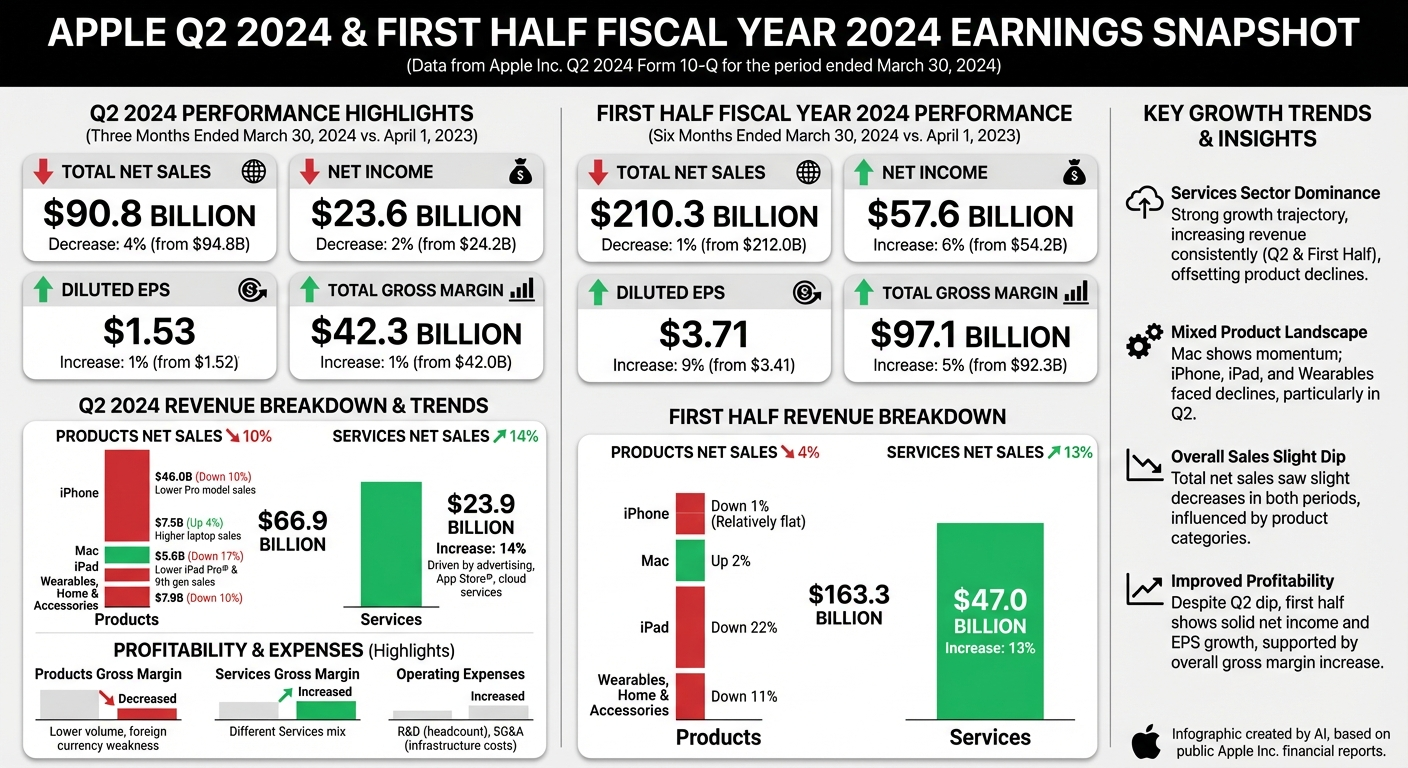

In [ ]:
display(Image(base64.b64decode(image_response.content_blocks[0]['base64'])))

In [ ]:
with open("data/images/apple_info.png", 'wb') as f:
    f.write(base64.b64decode(image_response.content_blocks[0]['base64']))